In [2]:
print("Dataset loaded:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Column names:")
    print(df.columns.tolist())
    display(df.head())

Dataset loaded: False


In [3]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError(
        "Please upload exactly one Employee Attrition CSV file."
    )

df = pd.read_csv(csv_files[0])
df.columns = df.columns.str.strip()

print("CSV loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (1).csv
CSV loaded successfully!
Dataset shape: (1470, 35)
Column names: ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:

# Step 4: Validate the Employee Attrition dataset

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

print("\nDuplicate rows:", df.duplicated().sum())

if "Attrition" in df.columns:
    print("\nAttrition distribution:")
    display(df["Attrition"].value_counts(dropna=False))
else:
    print("\nWARNING: 'Attrition' column not found.")


Dataset shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

First five rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Missing values:


,Missing Values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0



Duplicate rows: 0

Attrition distribution:


,count
Attrition,
No,1233
Yes,237


In [5]:

# STEP 6: Prepare features, target, and train/test split

from sklearn.model_selection import train_test_split

# Create a clean working copy
df_model = df.copy()
df_model.columns = df_model.columns.str.strip()

# Encode the target: No = 0, Yes = 1
df_model["Attrition"] = (
    df_model["Attrition"]
    .astype(str)
    .str.strip()
    .map({"No": 0, "Yes": 1})
)

# Validate target encoding
assert df_model["Attrition"].notna().all(), (
    "Unexpected target values found."
)

# Separate features and target
X = df_model.drop(columns=["Attrition"])
y = df_model["Attrition"].astype(int)

# Remove identifiers and constant administrative columns
# These do not provide useful employee-level predictive information.
columns_to_remove = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

X = X.drop(
    columns=[col for col in columns_to_remove if col in X.columns],
    errors="ignore"
)

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("STEP 6 COMPLETED")
print("-" * 40)
print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X.shape[1])

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)


STEP 6 COMPLETED
----------------------------------------
Total records: 1470
Training records: 1176
Testing records: 294
Number of features: 30

Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing target distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [6]:

# STEP 7: Leakage-safe preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for both data types
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("\nPREPROCESSING COMPLETED")
print("-" * 40)
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

assert X_train_processed.shape[0] == len(y_train)
assert X_test_processed.shape[0] == len(y_test)
assert X_train_processed.shape[1] == X_test_processed.shape[1]


Numerical features: 23
Categorical features: 7

Numerical columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

PREPROCESSING COMPLETED
----------------------------------------
Original training shape: (1176, 30)
Processed training shape: (1176, 51)
Original testing shape: (294, 30)
Processed testing shape: (294, 51)


In [9]:

# STEP 8: Define leakage-safe machine learning pipelines

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Model pipelines created successfully.")

for name, model in models.items():
    print(f"\n{name}")
    print(model)


Model pipelines created successfully.

Logistic Regression
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
  

In [10]:

# Train using only the training dataset

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    print(f"{name} training completed.")

print("\nSTEP 8 COMPLETED: Both models are trained.")


Training Logistic Regression...
Logistic Regression training completed.
Training Random Forest...
Random Forest training completed.

STEP 8 COMPLETED: Both models are trained.


In [11]:

# Verify fitted models and their prediction capabilities

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)

    print(f"\n{name}")
    print("Test predictions:", len(predictions))
    print("Probability matrix shape:", probabilities.shape)
    print("Predicted classes:", sorted(set(predictions)))

print("\nBoth models can generate predictions successfully.")



Logistic Regression
Test predictions: 294
Probability matrix shape: (294, 2)
Predicted classes: [np.int64(0), np.int64(1)]

Random Forest
Test predictions: 294
Probability matrix shape: (294, 2)
Predicted classes: [np.int64(0), np.int64(1)]

Both models can generate predictions successfully.


In [12]:

# STEP 9: Evaluate both trained models

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    # Predict the test-set classes
    y_pred = model.predict(X_test)

    # Get the probability assigned to attrition = 1
    positive_class_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test)[:, positive_class_index]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Build the comparison table
results_df = pd.DataFrame(results).set_index("Model")

print("MODEL EVALUATION RESULTS")
print("=" * 65)

display(results_df.round(4))


MODEL EVALUATION RESULTS


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
Random Forest,0.8469,0.6250,0.1064,0.1818,0.7903


In [13]:

# Identify the leading model by test-set F1 score

best_model_name = results_df["F1 Score"].idxmax()
best_f1 = results_df.loc[best_model_name, "F1 Score"]

print("Best model by F1 Score:", best_model_name)
print("F1 Score:", round(best_f1, 4))
print("Recall:", round(results_df.loc[best_model_name, "Recall"], 4))
print("Precision:", round(results_df.loc[best_model_name, "Precision"], 4))
print("ROC-AUC:", round(results_df.loc[best_model_name, "ROC-AUC"], 4))


Best model by F1 Score: Logistic Regression
F1 Score: 0.4511
Recall: 0.6383
Precision: 0.3488
ROC-AUC: 0.8032


In [14]:

# STEP 10: Display complete evaluation results

print("Complete test-set model comparison:")

display(
    results_df[
        ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
    ].round(4)
)


Complete test-set model comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
Random Forest,0.8469,0.6250,0.1064,0.1818,0.7903


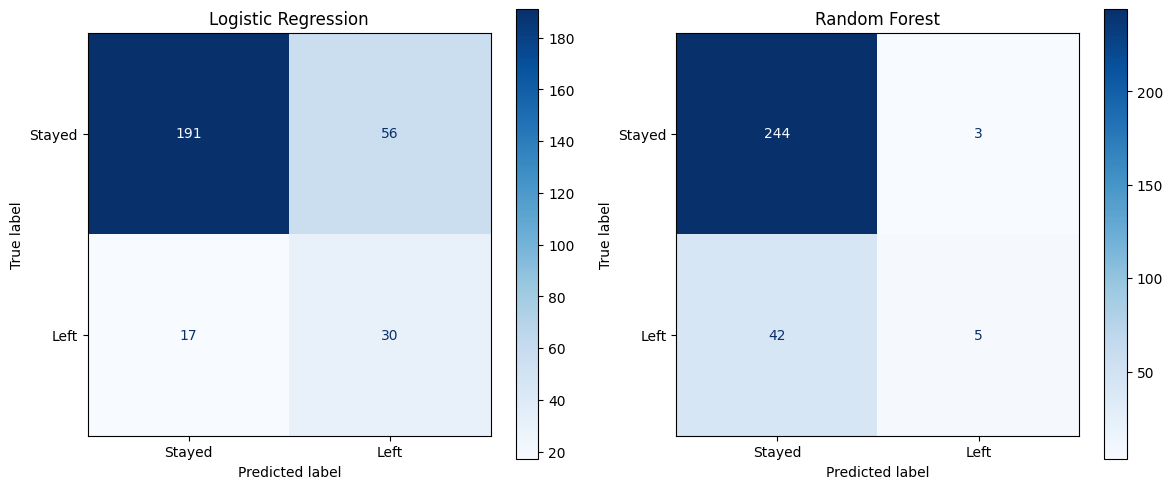

In [15]:

# Confusion matrices for both models

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=[0, 1],
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [16]:

print("Complete test-set model comparison:")
display(
    results_df[
        ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
    ].round(4)
)


Complete test-set model comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
Random Forest,0.8469,0.6250,0.1064,0.1818,0.7903


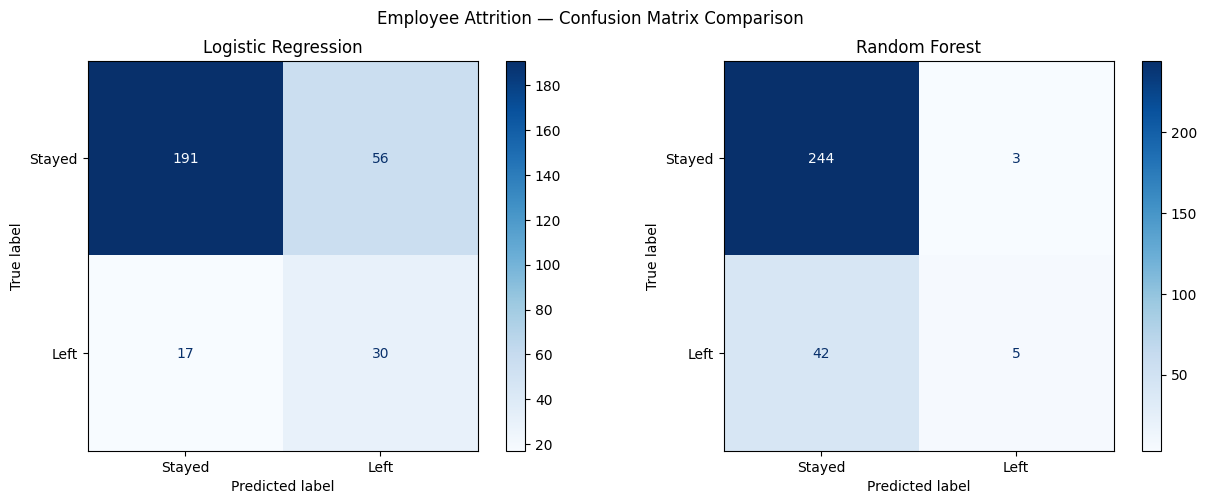

In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=[0, 1],
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        ax=ax,
        values_format="d"
    )
    ax.set_title(name)

plt.suptitle("Employee Attrition — Confusion Matrix Comparison")
plt.tight_layout()
plt.show()


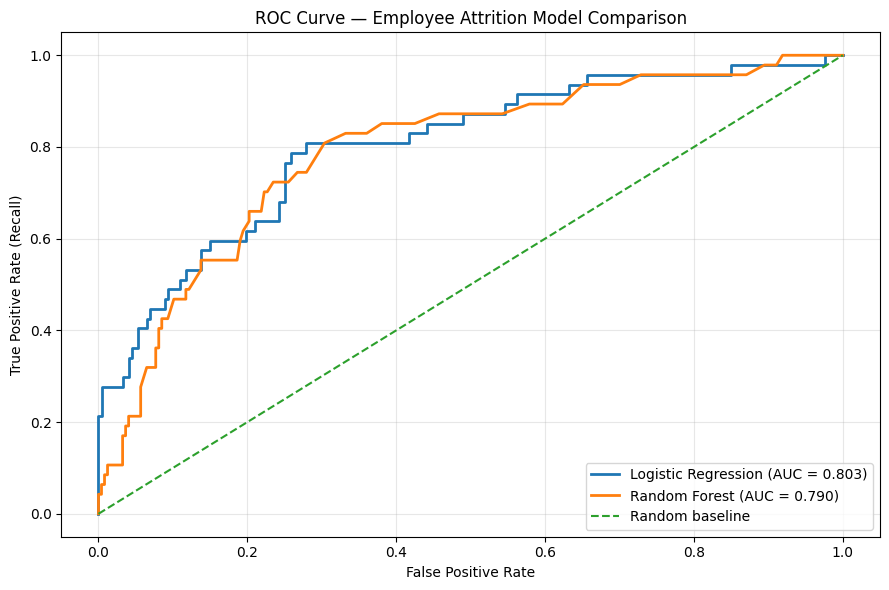

In [18]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Employee Attrition Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Build a fresh pipeline for tuning
tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Test several regularization strengths and class-weight settings
param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": ["balanced", None]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring={
        "recall": make_scorer(recall_score, zero_division=0),
        "precision": "precision",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    refit="recall",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean cross-validation recall:", round(grid_search.best_score_, 4))


Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Best mean cross-validation recall: 0.7579


In [20]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

tuned_model = grid_search.best_estimator_

# Evaluate the tuned model on the untouched test set
y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
    "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_tuned, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned)
}

comparison_df = pd.concat([
    results_df.reset_index(),
    pd.DataFrame([tuned_results]).set_index("Model").rename_axis("Model").reset_index()
], ignore_index=True)

display(
    comparison_df.set_index("Model")[
        ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
    ].round(4)
)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
Random Forest,0.8469,0.6250,0.1064,0.1818,0.7903
Tuned Logistic Regression,0.7687,0.3820,0.7234,0.5000,0.7985


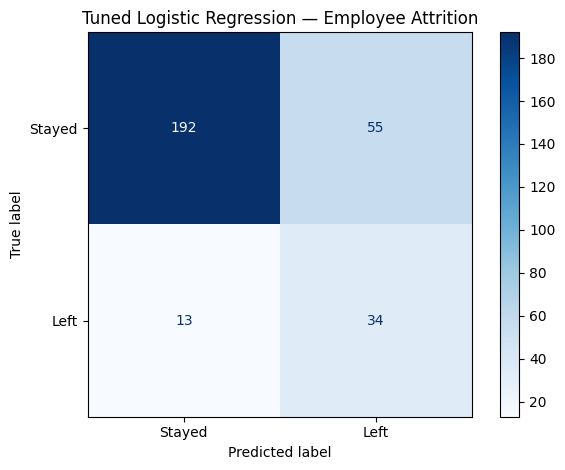

In [21]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    tuned_model,
    X_test,
    y_test,
    labels=[0, 1],
    display_labels=["Stayed", "Left"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned Logistic Regression — Employee Attrition")
plt.tight_layout()
plt.show()


In [22]:

import os
import json
import joblib
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create an artifacts folder
os.makedirs("artifacts", exist_ok=True)

# Save the tuned pipeline, including preprocessing
joblib.dump(
    tuned_model,
    "artifacts/employee_attrition_model.joblib"
)

# Calculate final tuned-model metrics
final_metrics = {
    "model": "Tuned Logistic Regression",
    "accuracy": float(accuracy_score(y_test, y_pred_tuned)),
    "precision": float(precision_score(y_test, y_pred_tuned, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred_tuned, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred_tuned, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, y_prob_tuned)),
    "test_samples": int(len(y_test)),
    "positive_class": "Yes (employee left)"
}

with open("artifacts/final_metrics.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

# Save the complete model comparison
comparison_df.to_csv(
    "artifacts/model_comparison.csv",
    index=False
)

print("Artifacts saved successfully:")
for filename in os.listdir("artifacts"):
    print("-", filename)

print("\nFinal tuned-model metrics:")
print(json.dumps(final_metrics, indent=4))


Artifacts saved successfully:
- employee_attrition_model.joblib
- model_comparison.csv
- final_metrics.json

Final tuned-model metrics:
{
    "model": "Tuned Logistic Regression",
    "accuracy": 0.7687074829931972,
    "precision": 0.38202247191011235,
    "recall": 0.723404255319149,
    "f1_score": 0.5,
    "roc_auc": 0.7985183909036093,
    "test_samples": 294,
    "positive_class": "Yes (employee left)"
}
